<a href="https://colab.research.google.com/github/670710713-chanatnun/lab-ai-69/blob/main/15_10_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install ultralytics easyocr gdown
!apt-get -qq install -y fonts-thai-tlwg > /dev/null      # ฟอนต์ไทยสำหรับกราฟ
import torch, ultralytics
print('มีการ์ดจอให้ใช้ไหม', torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 69.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 11.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
มีการ์ดจอให้ใช้ไหม False


In [2]:
import os, glob
ROOT = '/content/lpr'
FILE_ID = '1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt'           # lpr-week12-data.zip ชุดเดิมจากสัปดาห์ที่แล้ว
FILE_ID_W13 = '1aHz3xiJq3TcNv7nPTmBrr6d53F4ZclEv'        # lpr-week13-extra.zip มี best.pt กับเฉลยทะเบียน
if not os.path.exists(f'{ROOT}/gate'):
    !gdown {FILE_ID} -O /content/lpr-week12-data.zip
    !unzip -q /content/lpr-week12-data.zip -d {ROOT}
if not os.path.exists(f'{ROOT}/week13'):
    !gdown {FILE_ID_W13} -O /content/lpr-week13-extra.zip
    !unzip -q /content/lpr-week13-extra.zip -d {ROOT}
test_imgs = sorted(glob.glob(f'{ROOT}/gate/test/images/*'))
print('ภาพสอบ', len(test_imgs), 'ใบ')
print(open(f'{ROOT}/week13/README.txt', encoding='utf-8').read())

Downloading...
From (original): https://drive.google.com/uc?id=1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt
From (redirected): https://drive.google.com/uc?id=1-ZXdR3FtlZn_u1Mqf9qJ3pOnhYEgurAt&confirm=t&uuid=ceacd370-4ff6-43bc-a552-627090ba23da
To: /content/lpr-week12-data.zip
100% 90.8M/90.8M [00:02<00:00, 32.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1aHz3xiJq3TcNv7nPTmBrr6d53F4ZclEv
To: /content/lpr-week13-extra.zip
100% 5.65M/5.65M [00:00<00:00, 10.5MB/s]
ภาพสอบ 30 ใบ
lpr-week13-extra.zip
best.pt    สมองหาป้าย YOLOv8n ที่ซ้อมทวนด้วยภาพ gate/train 140 ใบ 30 รอบ (finetune จากสัปดาห์ที่ 12)
labels.csv เฉลยทะเบียนและจังหวัดของภาพ gate/test 30 ใบ ที่ผู้สอนอ่านด้วยตาเอง
           ใบที่จังหวัดว่างคือใบที่อ่านไม่ออก



In [3]:
import csv, re, unicodedata, time
import numpy as np
from PIL import Image

LABEL = {r['file']: r for r in csv.DictReader(open(f'{ROOT}/week13/labels.csv', encoding='utf-8'))}
TH_DIGIT = str.maketrans('๐๑๒๓๔๕๖๗๘๙', '0123456789')

def normalize(s):
    """ตัดช่องว่าง ขีด จุด และแปลงเลขไทยเป็นอารบิก ไม่แก้ตัวอักษรใดๆ"""
    return re.sub(r'[\s\-\.]', '', unicodedata.normalize('NFC', s)).translate(TH_DIGIT)

def crop_plate(path, box, pad=0):
    """ตัดภาพตามกรอบ (x0,y0,x1,y1) เผื่อขอบรอบด้าน pad จุด"""
    im = Image.open(path).convert('RGB'); W, H = im.size
    x0, y0, x1, y1 = box
    return im.crop((max(0, x0 - pad), max(0, y0 - pad), min(W, x1 + pad), min(H, y1 + pad)))

def parse(boxes, crop_height):
    """กล่องที่จุดกึ่งกลางอยู่เหนือ 58% ของความสูง = ทะเบียน ที่เหลือ = จังหวัด
    คืน (ทะเบียน, จังหวัดดิบ, ความมั่นใจต่ำสุดของกล่องทะเบียน)"""
    top = [b for b in boxes if np.mean([p[1] for p in b[0]]) < 0.58 * crop_height]
    bot = [b for b in boxes if np.mean([p[1] for p in b[0]]) >= 0.58 * crop_height]
    top.sort(key=lambda b: min(p[0] for p in b[0])); bot.sort(key=lambda b: min(p[0] for p in b[0]))
    reg = normalize(''.join(b[1] for b in top))
    prov = normalize(''.join(b[1] for b in bot))
    conf = min([float(b[2]) for b in top], default=0.0)
    return reg, prov, conf

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
for f in glob.glob('/usr/share/fonts/**/Loma*', recursive=True): fm.fontManager.addfont(f)
plt.rcParams['font.family'] = 'Loma'
GREEN, RED, ORANGE, GRAY = '#5f7a4a', '#b23b3b', '#b45309', '#9a948a'
print('เฉลย', len(LABEL), 'ใบ ตัวอย่าง', list(LABEL.values())[0])

เฉลย 30 ใบ ตัวอย่าง {'file': '20220516203717-34bc_wm_jpg.rf.e6a73a3015991de951d40f3ff79bc836.jpg', 'registration': '7กล9108', 'province': 'กรุงเทพมหานคร'}


In [4]:
from ultralytics import YOLO
finder = YOLO(f'{ROOT}/week13/best.pt')         # สมองหาป้ายจากสัปดาห์ที่แล้ว ถ้ามีของตัวเองก็ใช้ของตัวเองได้
BOX = {}
for p in test_imgs:
    r = finder.predict(p, imgsz=640, conf=0.25, verbose=False)[0]
    k = int(r.boxes.conf.argmax())                               # เอากรอบที่มั่นใจที่สุดหนึ่งกรอบต่อภาพ
    BOX[p] = [round(v) for v in r.boxes.xyxy[k].tolist()]
widths = [b[2] - b[0] for b in BOX.values()]
print('หาป้ายเจอ', len(BOX), 'จาก', len(test_imgs), 'ใบ  กรอบกว้าง', min(widths), 'ถึง', max(widths), 'จุด')

หาป้ายเจอ 30 จาก 30 ใบ  กรอบกว้าง 96 ถึง 275 จุด


In [5]:
import easyocr
t0 = time.time()
reader = easyocr.Reader(['th', 'en'], gpu=torch.cuda.is_available())
print('โหลดสมองอ่านหนังสือ %.1f วินาที' % (time.time() - t0))

p = test_imgs[2]                                 # ป้าย 1กฒ1753 ที่บทใช้เป็นตัวอย่าง
crop = crop_plate(p, BOX[p])
t0 = time.time(); boxes = reader.readtext(np.array(crop)); dt = time.time() - t0
print('อ่าน %.2f วินาที ได้ %d กล่อง' % (dt, len(boxes)))
for pts, text, conf in boxes:
    y = np.mean([q[1] for q in pts])
    print('%-16s มั่นใจ %.2f   กึ่งกลางสูง %.0f%% ของภาพ' % (text, conf, 100 * y / crop.height))

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Completeโหลดสมองอ่านหนังสือ 14.3 วินาที


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


อ่าน 5.91 วินาที ได้ 4 กล่อง
1753             มั่นใจ 1.00   กึ่งกลางสูง 32% ของภาพ
กรุงเทหมหานคร    มั่นใจ 0.36   กึ่งกลางสูง 62% ของภาพ
เกฒ              มั่นใจ 0.15   กึ่งกลางสูง 36% ของภาพ
wakaaty          มั่นใจ 0.04   กึ่งกลางสูง 76% ของภาพ


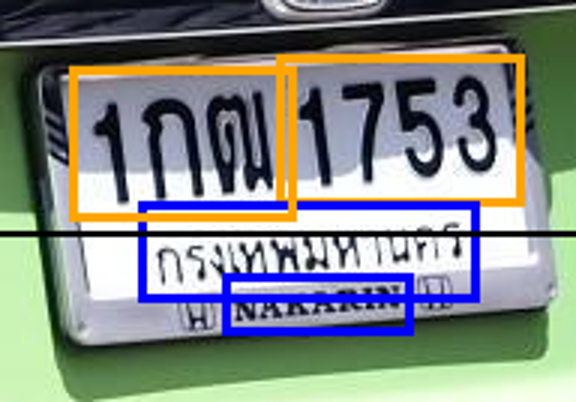

In [6]:
from PIL import ImageDraw
from IPython.display import display
im = crop.copy(); d = ImageDraw.Draw(im)
for pts, text, conf in boxes:
    xs = [q[0] for q in pts]; ys = [q[1] for q in pts]
    top = np.mean(ys) < 0.58 * crop.height
    d.rectangle([min(xs), min(ys), max(xs), max(ys)], outline='orange' if top else 'blue', width=3)
d.line([0, 0.58 * crop.height, crop.width, 0.58 * crop.height], fill='black', width=2)
display(im.resize((im.width * 3, im.height * 3)))

In [7]:
reg, prov, conf = parse(boxes, crop.height)
print('ทะเบียนที่อ่านได้', reg, ' จังหวัดดิบ', prov, ' มั่นใจต่ำสุดของทะเบียน %.2f' % conf)
print('ทะเบียนจริง      ', LABEL[os.path.basename(p)]['registration'])

ทะเบียนที่อ่านได้ เกฒ1753  จังหวัดดิบ กรุงเทหมหานครwakaaty  มั่นใจต่ำสุดของทะเบียน 0.15
ทะเบียนจริง       1กฒ1753


In [8]:
import pandas as pd
rows = []
for p in test_imgs:
    crop = crop_plate(p, BOX[p])
    t0 = time.time(); boxes = reader.readtext(np.array(crop)); dt = time.time() - t0
    reg, prov, conf = parse(boxes, crop.height)
    truth = LABEL[os.path.basename(p)]['registration']
    rows.append(dict(file=os.path.basename(p)[:14], read=reg, truth=truth, ok=reg == truth,
                     digits_ok=re.sub(r'\D', '', reg) == re.sub(r'\D', '', truth),
                     letters_ok=re.sub(r'[^ก-ฮ]', '', reg) == re.sub(r'[^ก-ฮ]', '', truth),
                     conf=round(conf, 2), width=BOX[p][2] - BOX[p][0], sec=round(dt, 2)))
df = pd.DataFrame(rows)
print(df.to_string(index=False))
print()
print('ถูกทั้งป้าย %d/30   ตัวเลขถูกหมด %d/30   พยัญชนะไทยถูกหมด %d/30   เวลากลางๆ %.2f วินาทีต่อใบ'
      % (df.ok.sum(), df.digits_ok.sum(), df.letters_ok.sum(), df.sec.median()))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


          file       read   truth    ok  digits_ok  letters_ok  conf  width   sec
20220516203717    7กล9108 7กล9108  True       True        True  0.97    173  5.97
20220516203721    7กล9108 7กล9108  True       True        True  0.98    176  4.19
20220718185915    เกฒ1753 1กฒ1753 False      False        True  0.15    192  5.20
20220728170738    9กฮ5961 9กฮ5961  True       True        True  0.99    174  2.97
20220728170738    9กฮ5961 9กฮ5961  True       True        True  0.99    275  2.42
20220728170739    9กฮ5961 9กฮ5961  True       True        True  0.97    166  4.84
20220819160212     ตกกาง( 6กก2536 False      False       False  0.06    162  2.74
20220914232916     พม1111  พม1111  True       True        True  0.66    180  4.57
20220915212650    8กค1018 8กค1018  True       True        True  0.57    153  3.25
20220916113635    9กด9225 9กด9225  True       True        True  0.29    134  2.31
20220918144959     ขท3329  ขท3329  True       True        True  0.79    217 12.28
20220921114511  

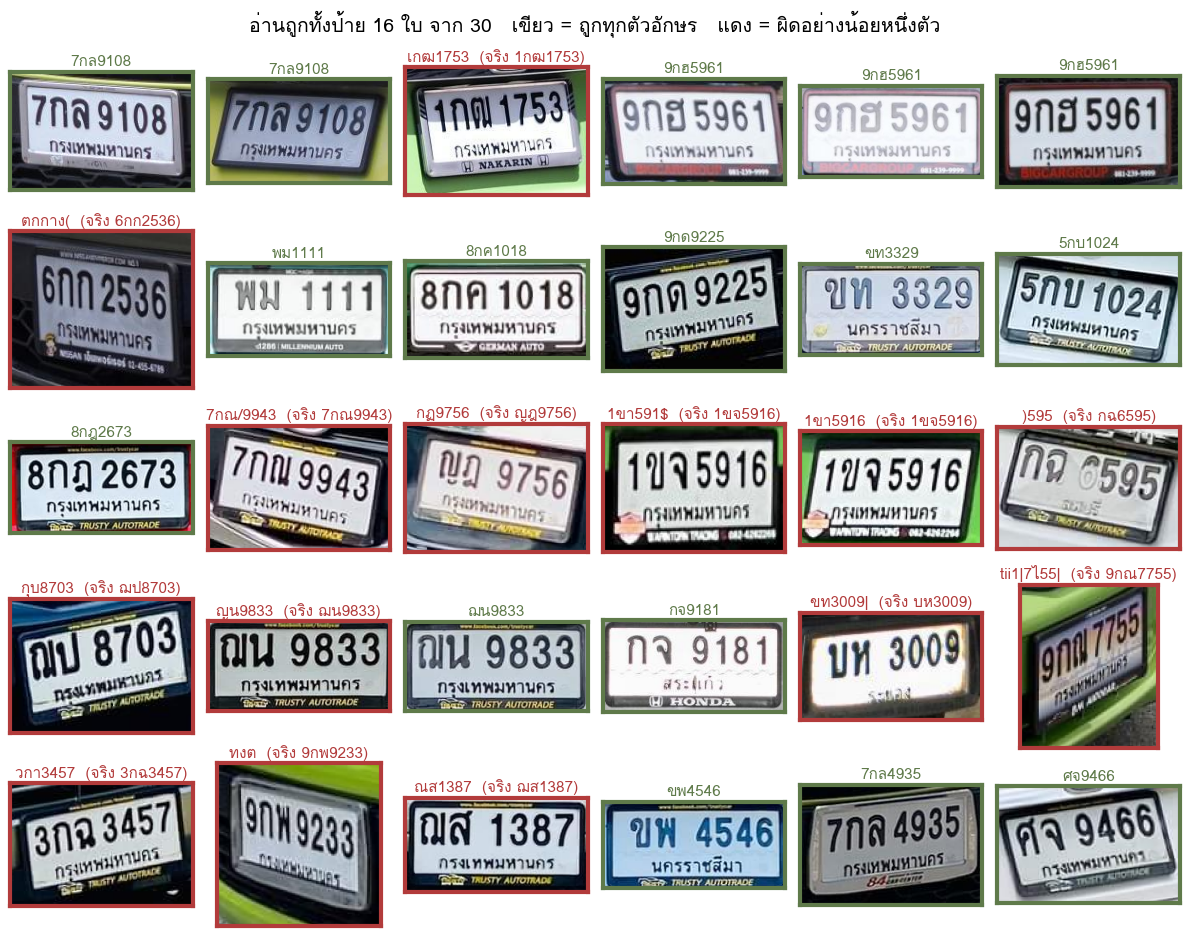

In [9]:
fig, axes = plt.subplots(5, 6, figsize=(12, 9.5))
for ax, p, r in zip(axes.flat, test_imgs, rows):
    ax.imshow(crop_plate(p, BOX[p])); ax.set_xticks([]); ax.set_yticks([])
    c = GREEN if r['ok'] else RED
    for sp in ax.spines.values(): sp.set_edgecolor(c); sp.set_linewidth(3)
    ax.set_title(r['read'] if r['ok'] else '%s  (จริง %s)' % (r['read'], r['truth']), fontsize=11, color=c, pad=4)
fig.suptitle('อ่านถูกทั้งป้าย %d ใบ จาก 30   เขียว = ถูกทุกตัวอักษร   แดง = ผิดอย่างน้อยหนึ่งตัว' % df.ok.sum(), fontsize=14)
plt.tight_layout(); plt.show()

In [10]:
small = df[df.width < 150]; big = df[df.width >= 150]
print('ป้ายแคบกว่า 150 จุด  อ่านถูก %d จาก %d' % (small.ok.sum(), len(small)))
print('ป้าย 150 จุดขึ้นไป   อ่านถูก %d จาก %d' % (big.ok.sum(), len(big)))

ป้ายแคบกว่า 150 จุด  อ่านถูก 1 จาก 9
ป้าย 150 จุดขึ้นไป   อ่านถูก 15 จาก 21


In [11]:
for th in [0.5, 0.8, 0.9]:
    passed = df[df.conf >= th]
    print('เส้นความมั่นใจ %.1f  ผ่าน %2d ใบ  ในนั้นผิด %d ใบ  อ่านถูกแต่ถูกทิ้ง %d ใบ'
          % (th, len(passed), (~passed.ok).sum(), (df.ok & (df.conf < th)).sum()))
wrong_but_sure = df[(~df.ok) & (df.conf >= 0.8)]
print(wrong_but_sure[['file', 'read', 'truth', 'conf']].to_string(index=False))

เส้นความมั่นใจ 0.5  ผ่าน 18 ใบ  ในนั้นผิด 4 ใบ  อ่านถูกแต่ถูกทิ้ง 2 ใบ
เส้นความมั่นใจ 0.8  ผ่าน  7 ใบ  ในนั้นผิด 0 ใบ  อ่านถูกแต่ถูกทิ้ง 9 ใบ
เส้นความมั่นใจ 0.9  ผ่าน  6 ใบ  ในนั้นผิด 0 ใบ  อ่านถูกแต่ถูกทิ้ง 10 ใบ
Empty DataFrame
Columns: [file, read, truth, conf]
Index: []


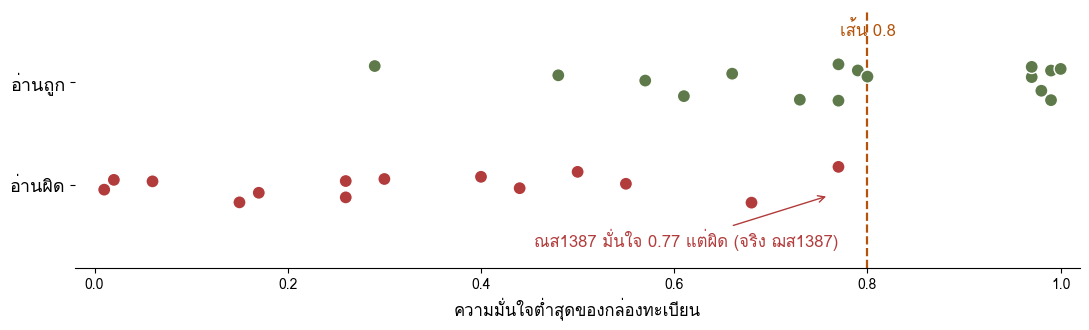

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.4))
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, len(df))
ax.scatter(df.conf, df.ok.astype(int) + jitter, s=90, c=np.where(df.ok, GREEN, RED), edgecolor='white', zorder=3)
ax.axvline(0.8, ls='--', color=ORANGE, lw=1.6); ax.text(0.8, 1.45, 'เส้น 0.8', color=ORANGE, ha='center', fontsize=12)
worst = df[(~df.ok)].sort_values('conf').iloc[-1]
ax.annotate('%s มั่นใจ %.2f แต่ผิด (จริง %s)' % (worst.read, worst.conf, worst.truth), (worst.conf - 0.01, -0.1), (0.77, -0.6),
            color=RED, fontsize=12, ha='right', arrowprops=dict(arrowstyle='->', color=RED))
ax.set_yticks([0, 1]); ax.set_yticklabels(['อ่านผิด', 'อ่านถูก'], fontsize=13); ax.set_ylim(-0.8, 1.7); ax.set_xlim(-0.02, 1.02)
ax.set_xlabel('ความมั่นใจต่ำสุดของกล่องทะเบียน', fontsize=12)
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

In [13]:
PADS = [0, 2, 4, 6, 8, 10, 12]
hits, READS, SCORE = {}, {}, []                   # hits[file] = [ถูกไหม ที่แต่ละขอบเผื่อ]
for pad in PADS:
    n_ok = 0
    for p in test_imgs:
        crop = crop_plate(p, BOX[p], pad)
        reg, _, _ = parse(reader.readtext(np.array(crop)), crop.height)
        ok = reg == LABEL[os.path.basename(p)]['registration']
        hits.setdefault(p, []).append(ok); READS.setdefault(p, []).append(reg); n_ok += ok
    SCORE.append(n_ok); print('เผื่อขอบ %2d จุด  อ่านถูก %d/30' % (pad, n_ok))
always = [p for p, h in hits.items() if all(h)]
never = [p for p, h in hits.items() if not any(h)]
flip = [p for p, h in hits.items() if any(h) and not all(h)]
print('ถูกทุกครั้ง %d ใบ  ผิดทุกครั้ง %d ใบ  แกว่ง %d ใบ' % (len(always), len(never), len(flip)))
for p in flip: print('  แกว่ง', os.path.basename(p)[:14], LABEL[os.path.basename(p)]['registration'], ''.join('O' if h else 'X' for h in hits[p]))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


เผื่อขอบ  0 จุด  อ่านถูก 16/30
เผื่อขอบ  2 จุด  อ่านถูก 15/30
เผื่อขอบ  4 จุด  อ่านถูก 13/30
เผื่อขอบ  6 จุด  อ่านถูก 16/30
เผื่อขอบ  8 จุด  อ่านถูก 16/30
เผื่อขอบ 10 จุด  อ่านถูก 14/30
เผื่อขอบ 12 จุด  อ่านถูก 16/30
ถูกทุกครั้ง 11 ใบ  ผิดทุกครั้ง 13 ใบ  แกว่ง 6 ใบ
  แกว่ง 20220916113635 9กด9225 OXXOXXX
  แกว่ง 20220921114511 5กบ1024 OOXOOXO
  แกว่ง 20220921120802 8กฎ2673 OOXOOOO
  แกว่ง 20220924155029 7กณ9943 XOXOOXO
  แกว่ง 20221007154203 กจ9181 OXOOOOO
  แกว่ง 20221112161143 ศจ9466 OOOXOOO


/tmp/ipykernel_2164/1416802281.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


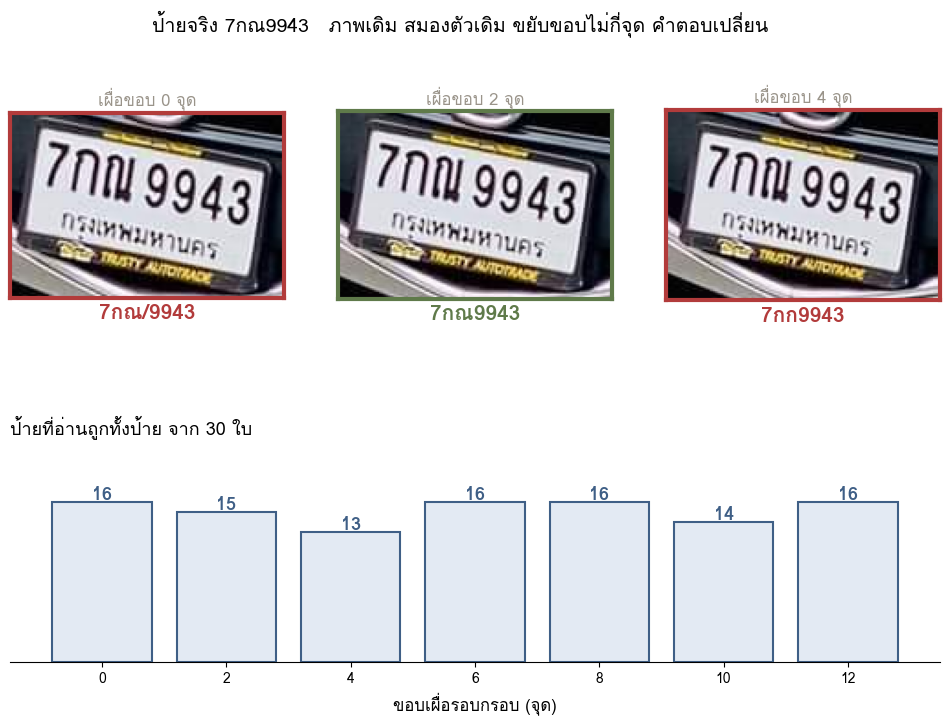

In [14]:
p = next((q for q in flip if LABEL[os.path.basename(q)]['registration'] == '7กณ9943'), flip[0])
fig = plt.figure(figsize=(12, 7.5)); gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 1], hspace=0.5)
for i, pad in enumerate(PADS[:3]):
    ax = fig.add_subplot(gs[0, i]); ax.imshow(crop_plate(p, BOX[p], pad)); ax.set_xticks([]); ax.set_yticks([])
    c = GREEN if hits[p][i] else RED
    for sp in ax.spines.values(): sp.set_edgecolor(c); sp.set_linewidth(3)
    ax.set_title('เผื่อขอบ %d จุด' % pad, fontsize=12, color=GRAY); ax.set_xlabel(READS[p][i], fontsize=15, color=c, fontweight='bold')
ax = fig.add_subplot(gs[1, :])
bars = ax.bar([str(x) for x in PADS], SCORE, color='#e3eaf3', edgecolor='#3f5f86', linewidth=1.5)
for b, v in zip(bars, SCORE): ax.text(b.get_x() + b.get_width() / 2, v + 0.3, str(v), ha='center', fontsize=13, color='#3f5f86', fontweight='bold')
ax.set_ylim(0, 22); ax.set_yticks([]); ax.set_xlabel('ขอบเผื่อรอบกรอบ (จุด)', fontsize=12); ax.set_title('ป้ายที่อ่านถูกทั้งป้าย จาก 30 ใบ', fontsize=13, loc='left')
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
fig.suptitle('ป้ายจริง %s   ภาพเดิม สมองตัวเดิม ขยับขอบไม่กี่จุด คำตอบเปลี่ยน' % LABEL[os.path.basename(p)]['registration'], fontsize=14)
plt.tight_layout(); plt.show()


In [15]:
groups = df.groupby('truth')
for truth, g in groups:
    if len(g) < 2: continue
    reads = list(g.read)
    verdict = 'ตรงกัน ' + ('และถูก' if reads[0] == truth else 'แต่ผิด') if len(set(reads)) == 1 else 'ไม่ตรงกัน ถือว่าไม่แน่ใจ'
    print('รถ %-8s ถ่าย %d ครั้ง อ่านได้ %-28s %s' % (truth, len(g), ' / '.join(reads), verdict))

รถ 1ขจ5916  ถ่าย 2 ครั้ง อ่านได้ 1ขา591$ / 1ขา5916            ไม่ตรงกัน ถือว่าไม่แน่ใจ
รถ 7กล9108  ถ่าย 2 ครั้ง อ่านได้ 7กล9108 / 7กล9108            ตรงกัน และถูก
รถ 9กฮ5961  ถ่าย 3 ครั้ง อ่านได้ 9กฮ5961 / 9กฮ5961 / 9กฮ5961  ตรงกัน และถูก
รถ ฌน9833   ถ่าย 2 ครั้ง อ่านได้ ญน9833 / ฌน9833              ไม่ตรงกัน ถือว่าไม่แน่ใจ


In [16]:
MEMBERS = {'7กล9108', '9กฮ5961', 'ขท3329', '1ขจ5916', 'ฌน9833', 'ศจ9466'}   # รายชื่อสมมติ 6 ทะเบียน

def decide(read):
    return 'เปิดไม้กั้น' if read in MEMBERS else 'เรียกเจ้าหน้าที่'

df['member'] = df.truth.isin(MEMBERS)
df['action'] = df.read.map(decide)
opened = df[df.action == 'เปิดไม้กั้น']
print('รถสมาชิกโผล่มา %d ครั้ง จากทั้งหมด 30 ครั้ง' % df.member.sum())
print('เปิดไม้กั้น %d ครั้ง  ในนั้นเปิดผิดคน %d ครั้ง' % (len(opened), (opened.read != opened.truth).sum()))
print('สมาชิกที่ต้องเรียกเจ้าหน้าที่ %d ครั้ง' % (df.member & (df.action != 'เปิดไม้กั้น')).sum())
print('คนนอกที่ถูกเปิดให้ %d ครั้ง' % (~df.member & (df.action == 'เปิดไม้กั้น')).sum())
print(df[df.member][['file', 'read', 'truth', 'action']].to_string(index=False))

รถสมาชิกโผล่มา 11 ครั้ง จากทั้งหมด 30 ครั้ง
เปิดไม้กั้น 8 ครั้ง  ในนั้นเปิดผิดคน 0 ครั้ง
สมาชิกที่ต้องเรียกเจ้าหน้าที่ 3 ครั้ง
คนนอกที่ถูกเปิดให้ 0 ครั้ง
          file    read   truth           action
20220516203717 7กล9108 7กล9108      เปิดไม้กั้น
20220516203721 7กล9108 7กล9108      เปิดไม้กั้น
20220728170738 9กฮ5961 9กฮ5961      เปิดไม้กั้น
20220728170738 9กฮ5961 9กฮ5961      เปิดไม้กั้น
20220728170739 9กฮ5961 9กฮ5961      เปิดไม้กั้น
20220918144959  ขท3329  ขท3329      เปิดไม้กั้น
20221002161313 1ขา591$ 1ขจ5916 เรียกเจ้าหน้าที่
20221002161320 1ขา5916 1ขจ5916 เรียกเจ้าหน้าที่
20221007144147  ญน9833  ฌน9833 เรียกเจ้าหน้าที่
20221007144148  ฌน9833  ฌน9833      เปิดไม้กั้น
20221112161143  ศจ9466  ศจ9466      เปิดไม้กั้น
